# Diffusion in 2D

We solve the heat equation with two space derivatives,

$$\frac{\partial u}{\partial t} = \alpha\left(
\frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2}\right),$$

on a square with the value held fixed on all four sides. This is Step 7 of Barba's twelve steps.

### Notation:

$$x \to i\,, \qquad y \to j\,, \qquad t \to n,$$

so a value is $u_{i,j}^{\,n}$ and we store it as `u[i, j, n]`, which extends the convention of nb07 to nb09 by one index.

### Numerical scheme:

Forward in time and centred in space in each direction:

$$u_{i,j}^{\,n+1} = u_{i,j}^{\,n} + r_x\left( u_{i+1,j}^{\,n} - 2u_{i,j}^{\,n} + u_{i-1,j}^{\,n} \right) + r_y\left( u_{i,j+1}^{\,n} - 2u_{i,j}^{\,n} + u_{i,j-1}^{\,n} \right),$$

$$r_x = \frac{\alpha\,\Delta t}{\Delta x^2}, \qquad
r_y = \frac{\alpha\,\Delta t}{\Delta y^2}, \qquad
r_x + r_y \le \tfrac{1}{2} \ \ \text{for stability}.$$

## Set-up: libraries and the grid

In [1]:
# Import libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### 1. Domain Definition (grid creation):

We take the unit square scaled to $0 \le x, y \le 2$, as in Barba's Step 7.

In [2]:
# Limits
x_min, x_max = 0., 2.
y_min, y_max = 0., 2.

# Number of points
ni = 81
nj = 81

# Resolution
dx = (x_max - x_min)/(ni - 1)
dy = (y_max - y_min)/(nj - 1)

# Axes
x = np.linspace(x_min, x_max, ni)
y = np.linspace(y_min, y_max, nj)

# A mesh for plotting, with i along x and j along y
X, Y = np.meshgrid(x, y, indexing = "ij")

### 2. Set up ICs/BCs:

The initial condition is a square hat: $u = 2$ on $0.5 \le x \le 1$ and $0.5 \le y \le 1$, and $u = 1$ elsewhere.

We hold $u = 1$ on all four boundaries.

In [3]:
def square_hat(x_mesh, y_mesh, lo = 0.5, hi = 1.0, u_low = 1., u_high = 2.):

    u_mat = np.full_like(x_mesh, u_low)
    u_mat[(x_mesh >= lo) & (x_mesh <= hi) & (y_mesh >= lo) & (y_mesh <= hi)] = u_high

    return u_mat

ics = square_hat(X, Y)

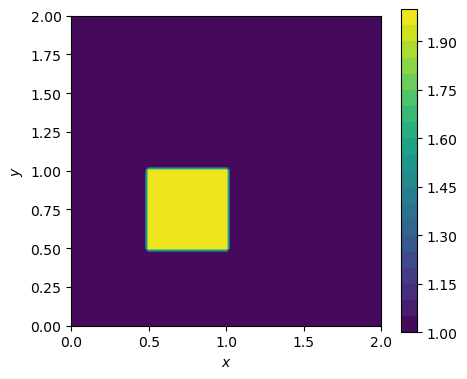

In [4]:
# Plotting

plt.figure(figsize=(5,4.2))

plt.contourf(X, Y, ics, levels = 21)

plt.xlabel(r"$x$")
plt.ylabel(r"$y$")

plt.colorbar()

plt.gca().set_aspect("equal")

plt.show()

### 3. Time discretisation:

We choose the time step from the stability limit. Writing
$r_{mesh} = r_x = r_y$ on a square grid, the condition $r_x + r_y \le 1/2$
becomes $r_{mesh} \le 1/4$.

In [5]:
# Diffusivity
alpha = 0.05

# r-values
r_x = r_y = 0.2

# Time step
dt = r_x*dx**2/alpha

# Number of time levels
nt = 41

t = np.arange(0., nt*dt, dt)

print(r_x,r_y)

0.2 0.2


### 4. Numerical integration:

$$u_{i,j}^{\,n+1} = u_{i,j}^{\,n} + r_x\left( u_{i+1,j}^{\,n} - 2u_{i,j}^{\,n} + u_{i-1,j}^{\,n} \right) + r_y\left( u_{i,j+1}^{\,n} - 2u_{i,j}^{\,n} + u_{i,j-1}^{\,n} \right),$$

The solution matrix now has three indices, `u[i, j, n]`.

In [6]:
def march_diffusion(ics_mat, alpha_num, dt_num, dx_num, dy_num, n_levels):

    u_mat = np.zeros((ics_mat.shape[0], ics_mat.shape[1], n_levels))

    u_mat[:, :, 0] = ics_mat

    rx = alpha_num*dt_num/dx_num**2
    ry = alpha_num*dt_num/dy_num**2

    # time loop (index n)
    for n in range(1, n_levels):

        u_old = u_mat[:, :, n-1]

        u_new = u_old.copy()

        u_new[1:-1, 1:-1] = (u_old[1:-1, 1:-1] + rx*(u_old[2:, 1:-1] - 2.*u_old[1:-1, 1:-1] + u_old[:-2, 1:-1]) + ry*(u_old[1:-1, 2:] - 2.*u_old[1:-1, 1:-1] + u_old[1:-1, :-2]))

        # boundaries held at the background value
        u_new[0, :] = 1.
        u_new[-1, :] = 1.
        u_new[:, 0] = 1.
        u_new[:, -1] = 1.

        u_mat[:, :, n] = u_new

    return u_mat

In [7]:
u_diff = march_diffusion(ics, alpha, dt, dx, dy, nt)

#print(u_diff.shape)

### 5. Plotting the solution:

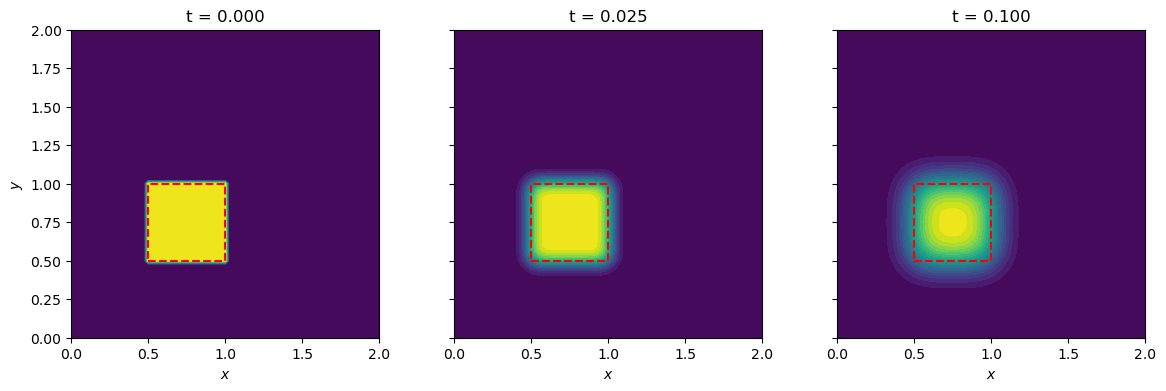

In [8]:
n_show = [0, 10, nt - 1]

fig, ax = plt.subplots(1, len(n_show), figsize = (14,4), sharey = True)

for a_i, n in zip(ax, n_show):

    a_i.contourf(X, Y, u_diff[:, :, n], levels = np.linspace(1., 2., 21))
    a_i.plot([0.5, 1., 1., 0.5, 0.5], [0.5, 0.5, 1., 1., 0.5], color = "r", lw = 1.5, ls = "--")
    a_i.set_title(f"t = {t[n]:.3f}")
    a_i.set_xlabel(r"$x$")
    a_i.set_aspect("equal")

ax[0].set_ylabel(r"$y$")

plt.show()

# Part II. The stability limit

The analysis gives $r_x + r_y \le 1/2$.

Let's measure it: we run the same problem at a few values of $r_{mesh} = r_x = r_y$ and watch the largest value in the field.

In [9]:
# r-values
r_x = r_y = 0.6

# Time step
dt = r_x*dx**2/alpha

# Number of time levels
nt = 41

t = np.arange(0., nt*dt, dt)

print(r_x,r_y)

0.6 0.6


In [10]:
u_diff = march_diffusion(ics, alpha, dt, dx, dy, nt)

#print(u_diff.shape)

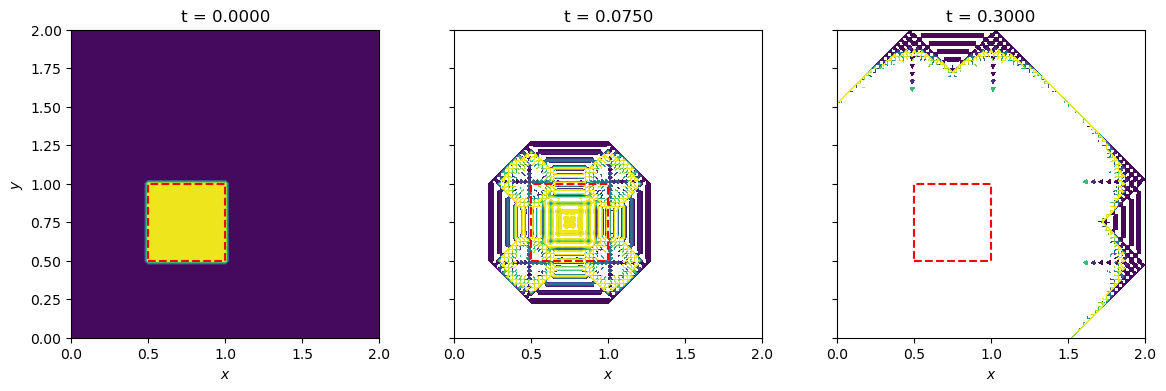

In [11]:
n_show = [0, 10, nt - 1]

fig, ax = plt.subplots(1, len(n_show), figsize = (14,4), sharey = True)

for a_i, n in zip(ax, n_show):

    a_i.contourf(X, Y, u_diff[:, :, n], levels = np.linspace(1., 2., 21))
    a_i.plot([0.5, 1., 1., 0.5, 0.5], [0.5, 0.5, 1., 1., 0.5], color = "r", lw = 1.5, ls = "--")
    a_i.set_title(f"t = {t[n]:.4f}")
    a_i.set_xlabel(r"$x$")
    a_i.set_aspect("equal")

ax[0].set_ylabel(r"$y$")

plt.show()

### Observations:

- The FTCS scheme becomes a five-point stencil scheme in 2D.

- The measured stability boundary is $r_x + r_y = 1/2$.

- In 1D the limit was $r \le 1/2$, so moving to 2D halves the time step at fixed mesh.
